Start speaking...
Recording complete


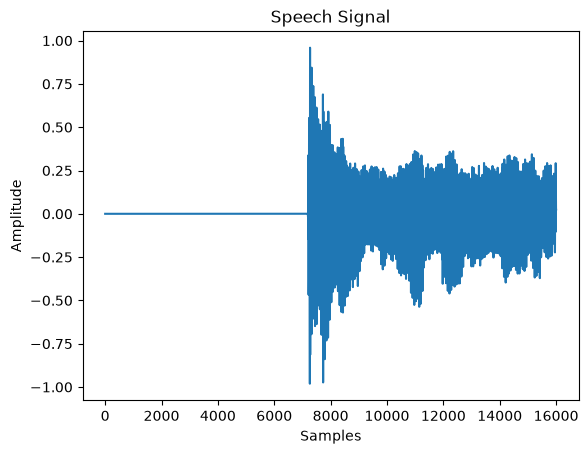

Saved successfully!


In [7]:
# Q1: Record a speech, plot it, and save the signal in Excel

import sounddevice as sd
import scipy.io.wavfile as wav
import matplotlib.pyplot as plt
import pandas as pd

fs = 8000
duration = 2

print("Start speaking...")
recording = sd.rec(int(duration * fs), samplerate=fs, channels=1)
sd.wait()
print("Recording complete")

wav.write("speech.wav", fs, recording)

fs, signal = wav.read("speech.wav")

plt.plot(signal)
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("Speech Signal")
plt.show()

df = pd.DataFrame({"Speech Signal": signal.flatten()})
df.to_excel("question1.xlsx", index=False)

print("Saved successfully!")

Original sampling frequency: 8000 Hz
New sampling frequency: 256 Hz
Original number of samples: 16000
After sampling: 517


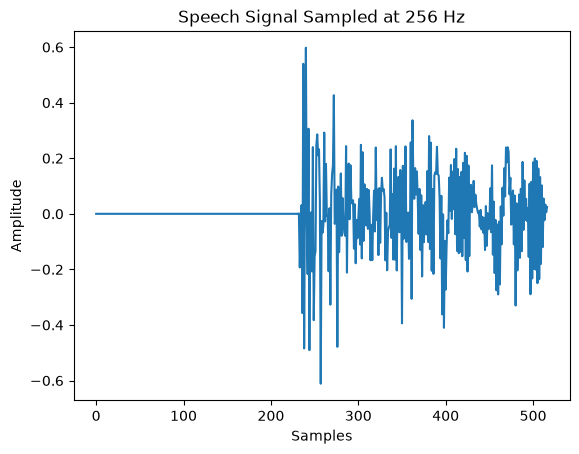

In [8]:
# Q2: Sample the speech signal at 256 Hz and compare the samples

import scipy.io.wavfile as wav
import matplotlib.pyplot as plt

fs, signal = wav.read("speech.wav")
signal = signal.flatten()

original_samples = len(signal)

new_fs = 256
step = fs // new_fs

sampled_signal = signal[::step]

sampled_samples = len(sampled_signal)

print("Original sampling frequency:", fs, "Hz")
print("New sampling frequency:", new_fs, "Hz")
print("Original number of samples:", original_samples)
print("After sampling:", sampled_samples)

plt.plot(sampled_signal)
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("Speech Signal Sampled at 256 Hz")
plt.show()

In [2]:
# Q3: Write a code to divide a speech signal (recording you have)
# into different segments (1s) and store it by different name.

import soundfile as sf
import numpy as np

x, sr = sf.read("speech.wav")

if x.ndim > 1:
    x = x.mean(axis=1)

for i, start in enumerate(range(0, len(x), sr)):
    sf.write(f"segment_{i+1}.wav", x[start:start+sr], sr)

print("Speech divided into 1-second segments.")

Speech divided into 1-second segments.


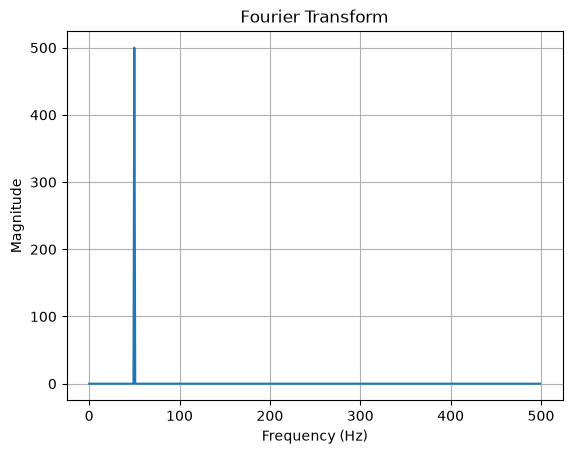

In [3]:
# Q4: Take sine wave and find the Fourier transform using Python.
# Check whether there is a keyword for finding Fourier transform
# or you have to implement the equation in coding.

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
t = np.arange(0, 1, 1/fs)
x = np.sin(2*np.pi*50*t)

X = np.fft.fft(x)
f = np.fft.fftfreq(len(x), 1/fs)

plt.plot(f[:len(f)//2], np.abs(X[:len(X)//2]))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Fourier Transform")
plt.grid()
plt.show()

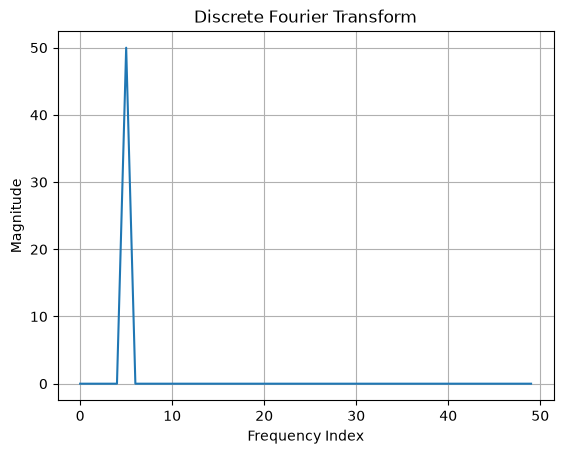

In [4]:
# Q5: Take sine wave and find the discrete Fourier transform using Python.
# Check whether there is a keyword for finding DFT or you have to
# implement the equation in coding.

import numpy as np
import matplotlib.pyplot as plt

N = 100
t = np.arange(N) / 100
x = np.sin(2*np.pi*5*t)
X = np.zeros(N, dtype=complex)

for k in range(N):
    for n in range(N):
        X[k] += x[n] * np.exp(-2j*np.pi*k*n/N)

plt.plot(np.abs(X[:N//2]))
plt.xlabel("Frequency Index")
plt.ylabel("Magnitude")
plt.title("Discrete Fourier Transform")
plt.grid()
plt.show()

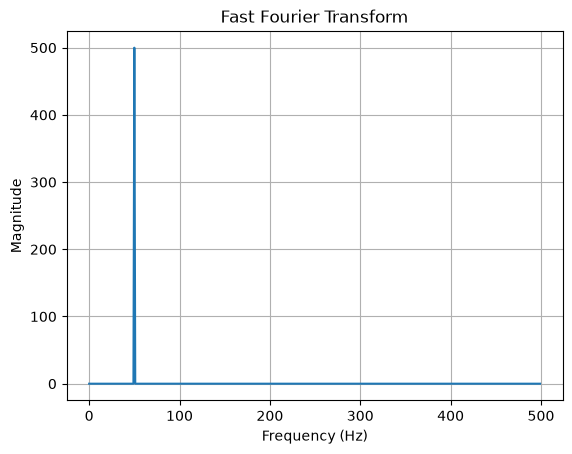

In [7]:
# Q6: Take sine wave and find the Fast Fourier transform using Python.
# Check whether there is a keyword for finding FFT or you have to
# implement the equation in coding.

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
t = np.arange(0, 1, 1/fs)
x = np.sin(2*np.pi*50*t)

X = np.fft.fft(x)
f = np.fft.fftfreq(len(x), 1/fs)

plt.plot(f[:len(f)//2], np.abs(X[:len(X)//2]))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Fast Fourier Transform")
plt.grid()
plt.show()

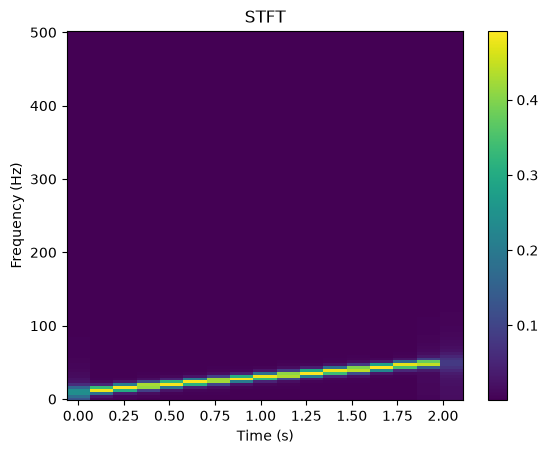

In [8]:
# Q7: Take variable sine wave and find the Short-Time Fourier
# transform using Python. Check whether a keyword exists for STFT
# or you have to implement the equation in coding.

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft

fs = 1000
t = np.arange(0, 2, 1/fs)
x = np.sin(2*np.pi*(10*t + 10*t**2))

f, ts, Z = stft(x, fs, nperseg=256)

plt.pcolormesh(ts, f, np.abs(Z), shading="auto")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("STFT")
plt.colorbar()
plt.show()

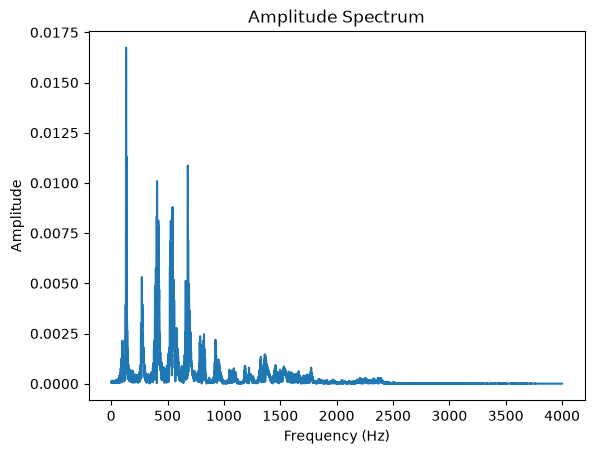

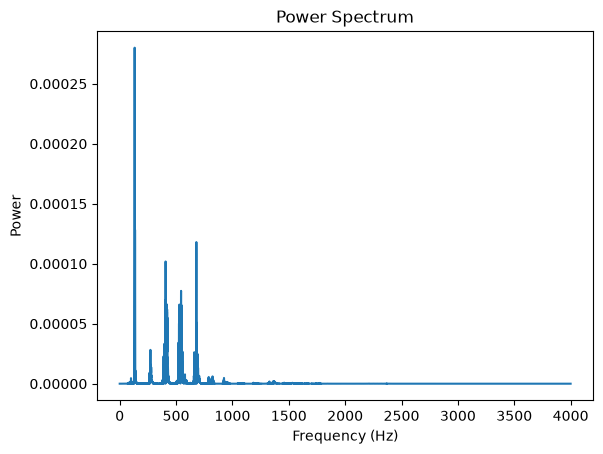

In [10]:
# Q8: Find the amplitude spectrum and power spectrum
# of a speech recording.

X = np.fft.rfft(x)
f = np.fft.rfftfreq(len(x), 1/sr)

amplitude = np.abs(X) / len(x)
power = amplitude**2

plt.plot(f, amplitude)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Amplitude Spectrum")
plt.show()

plt.plot(f, power)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.title("Power Spectrum")
plt.show()

First 10 FFT coefficients: [0.13558315+0.j         0.23280673+0.01578863j 0.14275349-0.01801284j
 0.2067042 +0.0465849j  0.14869655-0.03876766j 0.1727009 +0.04384128j
 0.18071102-0.05200703j 0.14217496+0.03993957j 0.19210819-0.05204512j
 0.130881  -0.01069987j]
STFT coefficient shape: (129, 17)


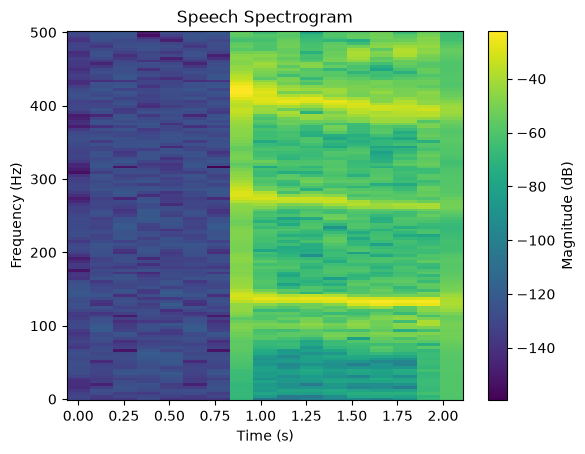

In [11]:
# Q9: Take a speech recording. Find the FFT and STFT coefficients
# present in the recording with a sampling frequency of 1000 Hz.
# Plot the spectrogram of the speech recording.

from scipy.signal import resample_poly, stft

y = resample_poly(x, 1000, sr)
fs = 1000

FFT = np.fft.rfft(y)
print("First 10 FFT coefficients:", FFT[:10])

f, t, Z = stft(y, fs=fs, nperseg=256)
print("STFT coefficient shape:", Z.shape)

plt.pcolormesh(t, f, 20*np.log10(np.abs(Z)+1e-10),
               shading="auto")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Speech Spectrogram")
plt.colorbar(label="Magnitude (dB)")
plt.show()

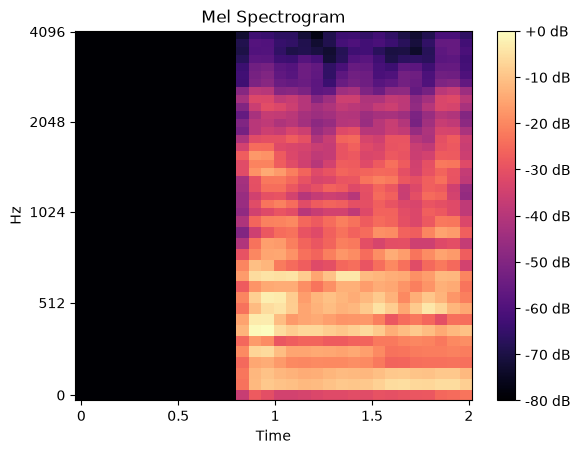

In [12]:
# Q10: Find the Mel spectrogram of a speech recording using Python.
# Plot it.

import librosa
import librosa.display

mel = librosa.feature.melspectrogram(
    y=x.astype(float), sr=sr, n_mels=40
)
mel_db = librosa.power_to_db(mel, ref=np.max)

librosa.display.specshow(
    mel_db, sr=sr, x_axis="time", y_axis="mel"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.show()

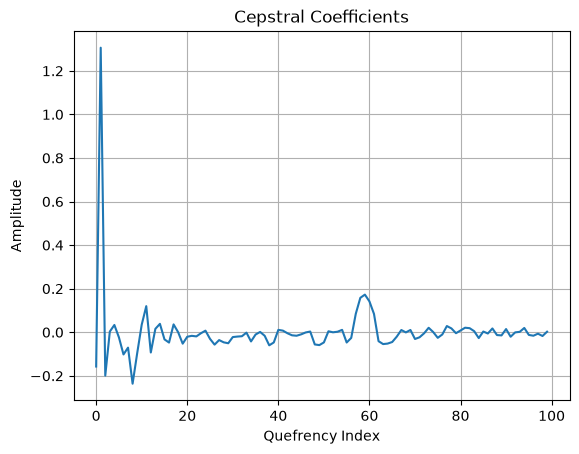

In [13]:
# Q11: Find the cepstral coefficients of a speech recording
# and plot it.

X = np.fft.fft(x)
cep = np.fft.ifft(np.log(np.abs(X)+1e-10)).real

plt.plot(cep[:100])
plt.xlabel("Quefrency Index")
plt.ylabel("Amplitude")
plt.title("Cepstral Coefficients")
plt.grid()
plt.show()

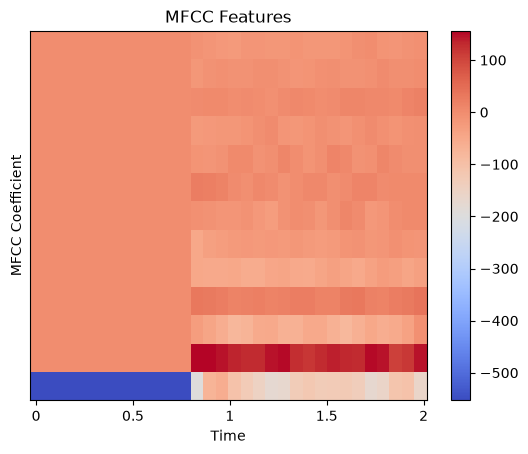

In [14]:
# Q12: Take a speech recording and find the MFCC features
# from the recording and plot it.

import librosa
import librosa.display

mfcc = librosa.feature.mfcc(
    y=x.astype(float), sr=sr, n_mfcc=13
)

librosa.display.specshow(mfcc, sr=sr, x_axis="time")
plt.colorbar()
plt.title("MFCC Features")
plt.ylabel("MFCC Coefficient")
plt.show()

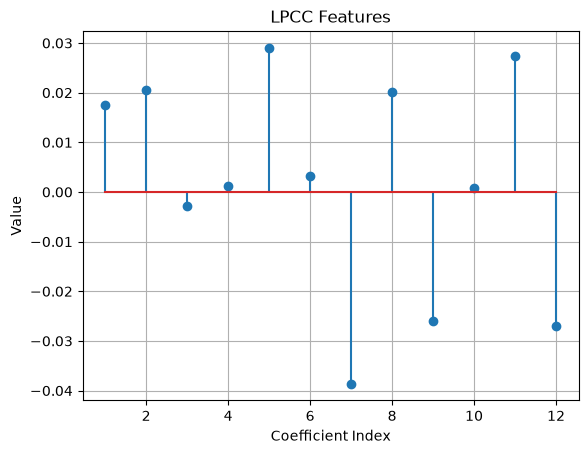

In [15]:
# Q13: Take a speech recording and find the LPCC features
# from the recording and plot it.

import librosa
import numpy as np
import matplotlib.pyplot as plt

frame = x[:min(len(x), 2048)]
frame = frame * np.hamming(len(frame))

order = 12
a = librosa.lpc(frame, order=order)
c = np.zeros(order+1)

for n in range(1, order+1):
    c[n] = -a[n]
    for k in range(1, n):
        c[n] -= (k/n) * c[k] * a[n-k]

plt.stem(range(1, order+1), c[1:])
plt.xlabel("Coefficient Index")
plt.ylabel("Value")
plt.title("LPCC Features")
plt.grid()
plt.show()